In [ ]:
from google.colab import files

uploaded = files.upload()

Saving PlayTennis.csv to PlayTennis.csv


Dataset:
        class handicapped_infants water_project_cost_sharing  \
0  republican                   n                          y   
1  republican                   n                          y   
2    democrat                 NaN                          y   
3    democrat                   n                          y   
4    democrat                   y                          y   

  adoption_of_budget_resolution physician_fee_freeze el_salvador_aid  \
0                             n                    y               y   
1                             n                    y               y   
2                             y                  NaN               y   
3                             y                    n             NaN   
4                             y                    n               y   

  religious_groups_in_schools anti_satellite_test_ban  \
0                           y                       n   
1                           y                       n   
2 

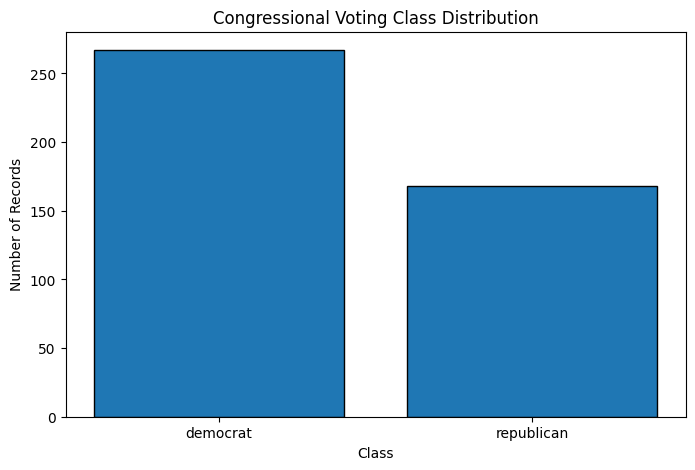

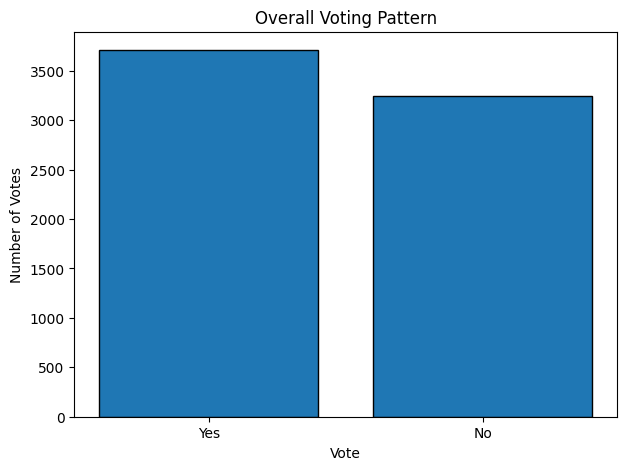

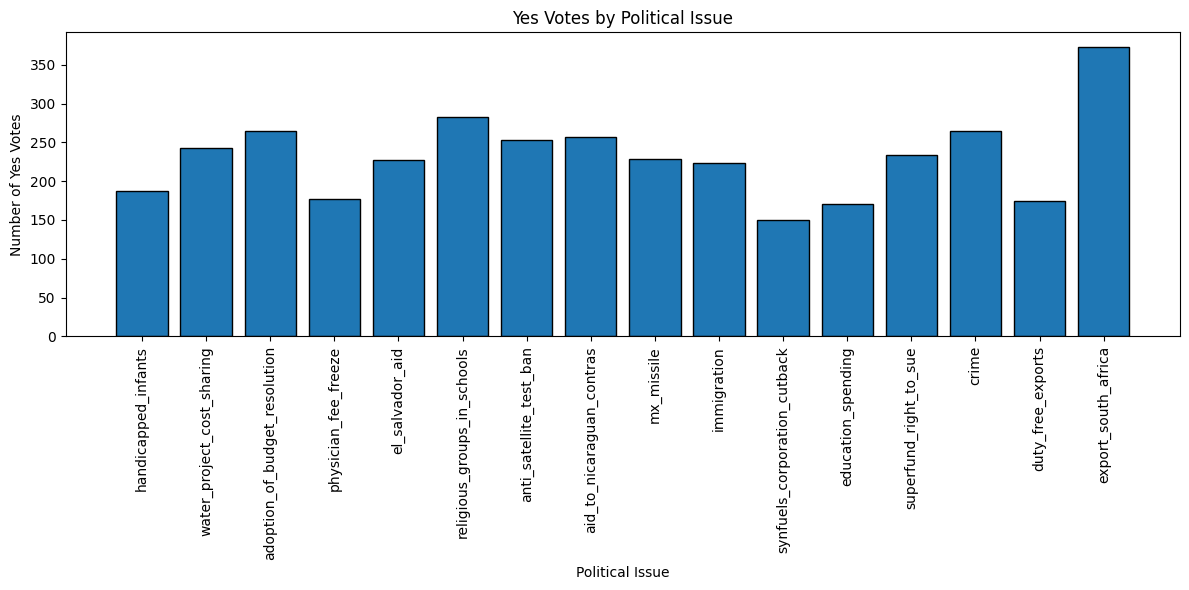

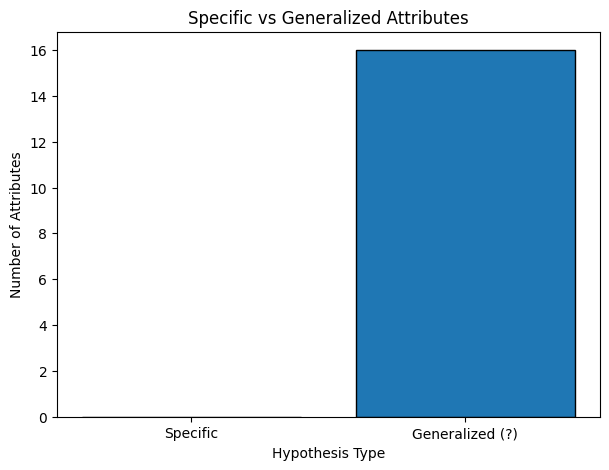


Cleaned dataset saved successfully.
Dataset:
  animal_name  hair  feathers  eggs  milk  airborne  aquatic  predator  \
0    aardvark     1         0     0     1         0        0         1   
1    antelope     1         0     0     1         0        0         0   
2        bass     0         0     1     0         0        1         1   
3        bear     1         0     0     1         0        0         1   
4        boar     1         0     0     1         0        0         1   

   toothed  backbone  breathes  venomous  fins  legs  tail  domestic  catsize  \
0        1         1         1         0     0     4     0         0        1   
1        1         1         1         0     0     4     1         0        1   
2        1         1         0         0     1     0     1         0        0   
3        1         1         1         0     0     4     0         0        1   
4        1         1         1         0     0     4     1         0        1   

   class_type  
0     

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------
# Load Congressional Voting Records Dataset
# ---------------------------------------------------

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/voting-records/house-votes-84.data"

columns = [
    "class",
    "handicapped_infants",
    "water_project_cost_sharing",
    "adoption_of_budget_resolution",
    "physician_fee_freeze",
    "el_salvador_aid",
    "religious_groups_in_schools",
    "anti_satellite_test_ban",
    "aid_to_nicaraguan_contras",
    "mx_missile",
    "immigration",
    "synfuels_corporation_cutback",
    "education_spending",
    "superfund_right_to_sue",
    "crime",
    "duty_free_exports",
    "export_south_africa"
]

df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset:")
print(df.head())


# ---------------------------------------------------
# Dataset Information
# ---------------------------------------------------

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["class"].value_counts())


# ---------------------------------------------------
# Handle Missing Values
# ---------------------------------------------------

for column in columns:
    if df[column].isnull().any():
        df[column] = df[column].fillna(
            df[column].mode()[0]
        )

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


# ---------------------------------------------------
# Prepare X and y
# ---------------------------------------------------

X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

attributes = list(df.columns[1:])


# ---------------------------------------------------
# Initial Specific and General Hypotheses
# ---------------------------------------------------

S = ["∅"] * len(attributes)

G = [["?"] * len(attributes)]


# ---------------------------------------------------
# Covers Function
# ---------------------------------------------------

def covers(h, x):

    for i in range(len(h)):

        if h[i] != "?" and h[i] != "∅":

            if h[i] != x[i]:
                return False

    return True


# ---------------------------------------------------
# Candidate Elimination Algorithm
# ---------------------------------------------------

for x, label in zip(X, y):

    # Positive Example
    if label == "democrat":

        # Remove general hypotheses
        # that do not cover positive example
        G = [
            g for g in G
            if covers(g, x)
        ]

        # First positive example
        if S == ["∅"] * len(attributes):

            S = list(x)

        else:

            # Generalize S
            for i in range(len(attributes)):

                if S[i] != x[i]:

                    S[i] = "?"


    # Negative Example
    elif label == "republican":

        new_G = []

        for g in G:

            # If G hypothesis covers negative example
            if covers(g, x):

                for i in range(len(attributes)):

                    if g[i] == "?":

                        if (
                            S[i] != "?"
                            and S[i] != "∅"
                        ):

                            h = g.copy()

                            h[i] = S[i]

                            if h not in new_G:

                                new_G.append(h)

            else:

                new_G.append(g)

        G = new_G


# ---------------------------------------------------
# Results
# ---------------------------------------------------

print("\nNumber of Positive Examples:")
print(sum(y == "democrat"))

print("\nNumber of Negative Examples:")
print(sum(y == "republican"))


print("\nMost Specific Hypothesis:")
print(S)


print("\nMost General Hypotheses:")

if len(G) == 0:

    print("Empty")

else:

    for g in G:
        print(g)


# ---------------------------------------------------
# Version Space
# ---------------------------------------------------

print("\nFinal Version Space:")

print("\nSpecific Boundary (S):")
print(S)

print("\nGeneral Boundary (G):")

if len(G) == 0:

    print("Empty")

else:

    for g in G:
        print(g)


# ---------------------------------------------------
# Graph 1: Class Distribution
# ---------------------------------------------------

class_counts = df["class"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    class_counts.index,
    class_counts.values,
    edgecolor="black"
)

plt.title("Congressional Voting Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")

plt.show()


# ---------------------------------------------------
# Graph 2: Yes vs No Votes
# ---------------------------------------------------

vote_columns = attributes

yes_count = 0
no_count = 0

for column in vote_columns:

    yes_count += (df[column] == "y").sum()
    no_count += (df[column] == "n").sum()

vote_data = {
    "Yes": yes_count,
    "No": no_count
}

plt.figure(figsize=(7, 5))

plt.bar(
    vote_data.keys(),
    vote_data.values(),
    edgecolor="black"
)

plt.title("Overall Voting Pattern")
plt.xlabel("Vote")
plt.ylabel("Number of Votes")

plt.show()


# ---------------------------------------------------
# Graph 3: Votes by Issue
# ---------------------------------------------------

issue_yes_votes = []

for column in vote_columns:

    issue_yes_votes.append(
        (df[column] == "y").sum()
    )


plt.figure(figsize=(12, 6))

plt.bar(
    vote_columns,
    issue_yes_votes,
    edgecolor="black"
)

plt.title("Yes Votes by Political Issue")
plt.xlabel("Political Issue")
plt.ylabel("Number of Yes Votes")

plt.xticks(
    rotation=90
)

plt.tight_layout()

plt.show()


# ---------------------------------------------------
# Graph 4: Hypothesis Boundary
# ---------------------------------------------------

specific_attributes = sum(
    1 for value in S
    if value != "?"
)

generalized_attributes = sum(
    1 for value in S
    if value == "?"
)

hypothesis_data = {
    "Specific": specific_attributes,
    "Generalized (?)": generalized_attributes
}

plt.figure(figsize=(7, 5))

plt.bar(
    hypothesis_data.keys(),
    hypothesis_data.values(),
    edgecolor="black"
)

plt.title("Specific vs Generalized Attributes")
plt.xlabel("Hypothesis Type")
plt.ylabel("Number of Attributes")

plt.show()


# ---------------------------------------------------
# Save Cleaned Dataset
# ---------------------------------------------------

df.to_csv(
    "Congressional_Voting_Cleaned.csv",
    index=False
)

print("\nCleaned dataset saved successfully.")












































































































import pandas as pd

# ---------------------------------------------------
# Load Zoo Dataset
# ---------------------------------------------------

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/zoo/zoo.data"

columns = [
    "animal_name",
    "hair",
    "feathers",
    "eggs",
    "milk",
    "airborne",
    "aquatic",
    "predator",
    "toothed",
    "backbone",
    "breathes",
    "venomous",
    "fins",
    "legs",
    "tail",
    "domestic",
    "catsize",
    "class_type"
]

df = pd.read_csv(
    url,
    header=None,
    names=columns
)

print("Dataset:")
print(df.head())


# ---------------------------------------------------
# Dataset Information
# ---------------------------------------------------

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["class_type"].value_counts())


# ---------------------------------------------------
# Prepare X and y
# ---------------------------------------------------

# Use animal characteristics as attributes
X = df.iloc[:, 1:-1].values

# Use class 1 (Mammal) as the positive class
y = df["class_type"].values

attributes = list(df.columns[1:-1])


# ---------------------------------------------------
# Initial Specific and General Hypotheses
# ---------------------------------------------------

S = ["∅"] * len(attributes)

G = [["?"] * len(attributes)]


# ---------------------------------------------------
# Covers Function
# ---------------------------------------------------

def covers(h, x):

    for i in range(len(h)):

        if h[i] != "?" and h[i] != "∅":

            if h[i] != x[i]:

                return False

    return True


# ---------------------------------------------------
# Candidate Elimination Algorithm
# ---------------------------------------------------

for x, label in zip(X, y):

    # Positive example: Mammal
    if label == 1:

        # Remove general hypotheses
        # that do not cover the positive example
        G = [
            g for g in G
            if covers(g, x)
        ]

        # First positive example
        if S == ["∅"] * len(attributes):

            S = list(x)

        else:

            # Generalize S
            for i in range(len(attributes)):

                if S[i] != x[i]:

                    S[i] = "?"


    # Negative example: Non-mammal
    else:

        new_G = []

        for g in G:

            # If G covers negative example
            if covers(g, x):

                for i in range(len(attributes)):

                    if g[i] == "?":

                        if (
                            S[i] != "?"
                            and S[i] != "∅"
                        ):

                            h = g.copy()

                            h[i] = S[i]

                            if h not in new_G:

                                new_G.append(h)

            else:

                new_G.append(g)

        G = new_G


# ---------------------------------------------------
# Display Results
# ---------------------------------------------------

print("\nNumber of Positive Examples (Mammals):")
print(sum(y == 1))

print("\nNumber of Negative Examples:")
print(sum(y != 1))


print("\nMost Specific Hypothesis:")
print(S)


print("\nMost General Hypotheses:")

if len(G) == 0:

    print("Empty")

else:

    for g in G:

        print(g)


# ---------------------------------------------------
# Final Version Space
# ---------------------------------------------------

print("\nFinal Version Space:")

print("\nSpecific Boundary (S):")
print(S)

print("\nGeneral Boundary (G):")

if len(G) == 0:

    print("Empty")

else:

    for g in G:

        print(g)


# ---------------------------------------------------
# Save Cleaned Dataset
# ---------------------------------------------------

df.to_csv(
    "Zoo_Cleaned.csv",
    index=False
)

print("\nCleaned dataset saved successfully.")
















































import pandas as pd

# Direct dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data"

# Column names
columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

# Load dataset
df = pd.read_csv(url, header=None, names=columns)

print("Dataset:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nClass Distribution:")
print(df["class"].value_counts())

# Attributes
attributes = columns[:-1]

# Initialize hypothesis
hypothesis = ["∅"] * len(attributes)

# Find-S Algorithm
for index, row in df.iterrows():

    # Consider positive examples
    # Here, "acc" is considered the positive class
    if row["class"] == "acc":

        # First positive example
        if hypothesis == ["∅"] * len(attributes):
            hypothesis = list(row[attributes])

        else:
            # Compare attributes
            for i in range(len(attributes)):

                if hypothesis[i] != row[attributes[i]]:
                    hypothesis[i] = "?"

print("\nFinal Hypothesis:")
print(hypothesis)


print("\nCandidate Elimination completed successfully.")
print("\nCandidate Elimination completed successfully.")